In [ ]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [4]:
import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
# sns.set()
sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
# from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches
from f2_utils import *
import time_in_each_roi
import matplotlib

In [5]:
prefix = '/mnt/staging/'
step_0_root = str(STEPS / "step_0") + "/"
step_1_root = str(STEPS / "step_1") + "/"
step_2_root = str(STEPS / "step_2") + "/"
step_3_root = str(STEPS / "step_3") + "/"

fetch_path_S1 = str(PREPARES / "index-S1") + "/"
fetch_path_M2 = str(PREPARES / "index-M2") + "/"
fetch_path_M1 = str(PREPARES / "index-M1") + "/"
fetch_path_extra = str(PREPARES / "index-extra") + "/"
figure_config_root = str(PREPARES / "config") + "/"

mouse='cm229'
h5_root = step_3_root+mouse+'/dlc_h5s/'
mirror_h5_root = step_3_root+mouse+'/dlc_mirror_h5s/'


data_root =  str(PREPARES / "epochs-rest-to-running") + "/"


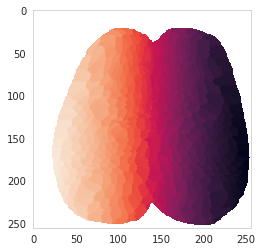

In [6]:
with h5py.File(step_0_root+mouse+'/idx_sorted_500_'+mouse+'.mat','r') as f_idx:

    IDX_sorted = np.array(f_idx['IDX_sorted']).T
    IDX_sorted = IDX_sorted.astype(float)
    IDX_sorted[IDX_sorted==0]='nan'
    num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
    props = regionprops(IDX_sorted.astype(int))
    node_coords = [props[i].centroid for i in range(len(props))]
    node_coords = np.asarray(node_coords, dtype=np.float32)
plt.imshow(IDX_sorted)

In [7]:
mouse_id = mouse
   
M2_ind = load_pickle(fetch_path_M2+'brightest_frontline_ind-'+mouse_id)
sensory_ind = load_pickle(fetch_path_S1+'brightest_ind_'+mouse_id)


In [8]:
session_name  = 'cm229_4_runC'
# session_name  = 'cm229_5_runD'

**load data**

In [9]:
def IsPointInROI(x1, y1, x2, y2, x, y) : 
    if (x > x1 and x < x2 and y > y1 and y < y2) : 
        return True
    else: 
        return False

In [10]:
fname = list(set(glob.glob(step_2_root+"*229/4/H_*[C]*.mat")) )[0]

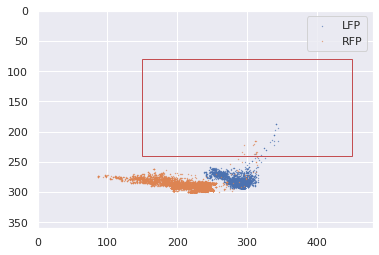

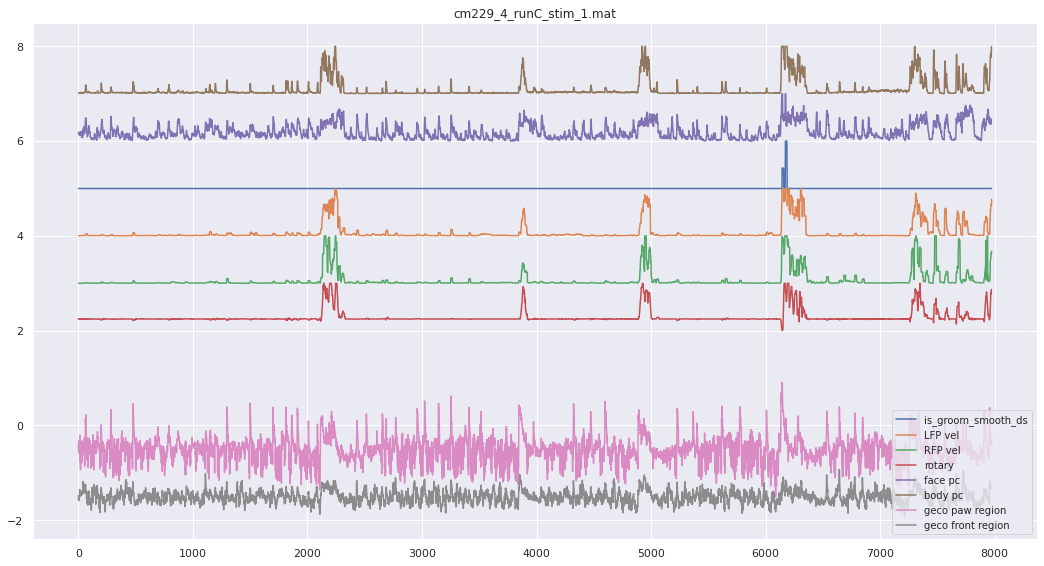

In [11]:
sns.set()
import warnings
warnings.filterwarnings('ignore')
###################################################################### M setting

T_PRE = 30
T_POST = 90
T=T_PRE+T_POST
num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1)))) 

M_jrgeco = np.empty((num_regions,T,0))
M_gcamp = np.empty((num_regions,T,0))
M_chbt = np.empty((num_regions,T,0))

M_day_label =  np.empty((0))
M_face_pc = np.empty((T,0))
M_body_pc = np.empty((T,0))
M_LFP_vel = np.empty((T,0))
M_RFP_vel = np.empty((T,0))
M_rotf = np.empty((T,0))
M_rotf_smooth = np.empty((T,0))
M_ind = np.empty((0))
M_is_groom = np.empty((T,0))
M_body_pc_smooth = np.empty((T,0))

M_mirrorRFP_vel = np.empty((T,0))
M_mirrorRFP_vel_norm = np.empty((T,0))
M_mirrorLFP_vel = np.empty((T,0))
M_mirrorLFP_vel_norm = np.empty((T,0))
M_mirrorRHP_vel = np.empty((T,0))
M_mirrorRHP_vel_norm = np.empty((T,0))
M_mirrorLHP_vel = np.empty((T,0))
M_mirrorLHP_vel_norm = np.empty((T,0))




f = h5py.File(fname,'r')
################################### identity 
split1=fname.split('/H_')
run_name = split1[1]
run = run_name[:4]
day=split1[0].split(mouse+'/')[1]
mouse_day = mouse+'_'+day


with h5py.File(fname,'r') as f_H: 
    H = np.array(f_H['H']).transpose() #(36,11975)       
    H = H[:,500:-505]#^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^trimming
    total_tpt=H.shape[-1]
    H_gcamp = np.array(f_H['H_gcamp']).transpose() #(36,11975)       
    H_gcamp = H_gcamp[:,500:-505]#^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^trimming
    H_chbt = np.array(f_H['H_chbt']).transpose() #(36,11975)       
    H_chbt = H_chbt[:,500:-505]#^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^trimming

    m=f_H['m']
    a=np.array(m['DAQ_ds'])
    rot = np.rad2deg(np.unwrap(a[:,-1]))
    rot = np.diff(rot)
    z = np.abs(stats.zscore(rot))
    threshold = 5
    outlier_ind = np.squeeze(np.where(z > 5))
    rot[outlier_ind]=np.nan
    rot_smooth = np.array(stats.zscore(np.squeeze(pd.DataFrame(rot).interpolate().rolling(20).mean().fillna(0))))
    rot_smooth = rot_smooth[500:-506]
    rot_2_detect = np.array(stats.zscore(np.squeeze(pd.DataFrame(rot).interpolate().rolling(20).std().rolling(20).mean().fillna(0))))
    rot_2_detect = rot_2_detect[500:-506]



f_name_dlc = glob.glob(h5_root + mouse_day+'_'+run+"*h5", recursive=True)[0] # target at specific run
Dataframe = pd.read_hdf(f_name_dlc)
scorer = Dataframe.keys()[0][0] #'DLC_resnet101_whiskeyOct2shuffle1_252000'
new_df = Dataframe[scorer] # de-level

paws_vel_df = pd.DataFrame()
bodyparts=Dataframe.columns.get_level_values(1).drop_duplicates()

for i_bpt,bpt in enumerate(['LFP','RFP']):#make sure RFP comes out last
    vel = time_in_each_roi.calc_distance_between_points_in_a_vector_2d(np.vstack([new_df[bpt]['x'].values.flatten(), new_df[bpt]['y'].values.flatten()]).T)
    vel_smooth = pd.DataFrame(vel).rolling(60).std()
    vel = pd.DataFrame(vel).rolling(60).std()
    tocut = vel.shape[0]%4
    if tocut ==0:
        vel = np.mean(vel.values.reshape((-1,4)),axis=1)
        vel_smooth = np.mean(vel_smooth.values.reshape((-1,4)),axis=1)
    else:
        vel = np.mean(vel[:-tocut].values.reshape((-1,4)),axis=1)  
        vel_smooth = np.mean(vel_smooth[:-tocut].values.reshape((-1,4)),axis=1) 

    paws_vel_df[bpt] = stats.zscore(vel[500:-505])
    vel_ds = paws_vel_df[bpt].copy()
    vel_ds[vel_ds>7]=np.nan;
    paws_vel_df[bpt]=vel_ds
    paws_vel_df[bpt] = paws_vel_df[bpt].fillna(0)
    paws_vel_df[bpt]=np.array(paws_vel_df[bpt].interpolate())

    vel_smooth = stats.zscore(vel_smooth[500:-505])
    vel_smooth[vel_smooth>7]=np.nan;
    vel_smooth=np.array(pd.DataFrame(vel_smooth).interpolate())


LFP_vel = stats.zscore(np.array(paws_vel_df['LFP']))
RFP_vel = stats.zscore(np.array(paws_vel_df['RFP']))


# is_groom plot # (480,360)
import matplotlib.patches as patches

x_top_left=80
x_botton_right=240
y_top_left=150
y_botton_right=450

out_h = int(x_botton_right - x_top_left)
out_w = int(y_botton_right - y_top_left)
y = x_top_left
x = y_top_left

fig,ax = plt.subplots(1)
plt.scatter(new_df['LFP']['x'],new_df['LFP']['y'],s=0.1,label='LFP')
plt.scatter(new_df['RFP']['x'],new_df['RFP']['y'],s=0.1,label='RFP')
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='r',facecolor='none')
plt.ylim([0,360])
plt.xlim([0,480])
plt.legend()
ax.add_patch(rect)
plt.gca().invert_yaxis()      


is_groom_LFP = new_df.apply(lambda row: IsPointInROI(x, y, x+out_w, y+out_h,row['LFP']['x'], row['LFP']['y']), axis=1)
is_groom_RFP = new_df.apply(lambda row: IsPointInROI(x, y, x+out_w, y+out_h,row['RFP']['x'], row['RFP']['y']), axis=1)
is_groom = np.logical_and(is_groom_LFP,is_groom_RFP)
is_groom_smooth = is_groom.rolling(60).mean()
if tocut ==0:
    is_groom_smooth_ds = np.mean(is_groom_smooth.values.reshape((-1,4)),axis=1)
else:
    is_groom_smooth_ds = np.mean(is_groom_smooth[:-tocut].values.reshape((-1,4)),axis=1) #(11980,)
is_groom_smooth_ds = is_groom_smooth_ds[500:-505]

is_groom_smooth_ds = normalize(is_groom_smooth_ds)

if tocut ==0:
    new_df = new_df.groupby(np.arange(new_df.shape[0])//4, axis=0).mean()
else:
    new_df = new_df[:-tocut].groupby(np.arange(new_df[:-tocut].shape[0])//4, axis=0).mean()

new_df = new_df.iloc[500:-505]



f_name_dlc = glob.glob(mirror_h5_root + mouse_day+'_'+run+"*h5", recursive=True)[0] # target at specific run
Dataframe = pd.read_hdf(f_name_dlc)
scorer = Dataframe.keys()[0][0] #'DLC_resnet101_whiskeyOct2shuffle1_252000'
new_df_2 = Dataframe[scorer] # de-level

paws_vel_df = pd.DataFrame()
bodyparts=Dataframe.columns.get_level_values(1).drop_duplicates()

for i_bpt,bpt in enumerate(['LFP','RFP','LHP','RHP']):
    vel = time_in_each_roi.calc_distance_between_points_in_a_vector_2d(np.vstack([new_df_2[bpt]['x'].values.flatten(), new_df_2[bpt]['y'].values.flatten()]).T)
    vel = pd.DataFrame(vel).rolling(40).std()
    tocut = vel.shape[0]%4
    if tocut ==0:
        vel = np.mean(vel.values.reshape((-1,4)),axis=1)
    else:
        vel = np.mean(vel[:-tocut].values.reshape((-1,4)),axis=1)   
    paws_vel_df[bpt] = vel[500:-505]

mirrorLFP_vel = np.array(paws_vel_df['LFP'])
mirrorRFP_vel = np.array(paws_vel_df['RFP'])
mirrorLHP_vel = np.array(paws_vel_df['LHP'])
mirrorRHP_vel = np.array(paws_vel_df['RHP'])

mirrorLFP_vel_norm = stats.zscore(mirrorLFP_vel)
mirrorRFP_vel_norm = stats.zscore(mirrorRFP_vel)
mirrorLHP_vel_norm = stats.zscore(mirrorLHP_vel)
mirrorRHP_vel_norm = stats.zscore(mirrorRHP_vel)

if tocut ==0:
    new_df_2 = new_df_2.groupby(np.arange(new_df_2.shape[0])//4, axis=0).mean()
else:
    new_df_2 = new_df_2[:-tocut].groupby(np.arange(new_df_2[:-tocut].shape[0])//4, axis=0).mean()
new_df_2 = new_df_2.iloc[500:-505]

data_pot = pd.concat([new_df,new_df_2],
                 keys=['front','mirror'],names=['column_level'],axis=1)


with(h5py.File(pjoin(step_3_root,
                         mouse,day,run+'_cam_pc.mat'),'r')) as f_b:
    motionS = f_b['motionS']# this is the HDF5 reference
    motion_pc = {key: [] for key in list(motionS.keys())} 
    motion_pc_2detect = {key: [] for key in list(motionS.keys())} 
    for key in list(motionS.keys()):

        motion_pc[key] = pd.DataFrame(motionS[key]).transpose()# this is the actual data
        # (200,T)
        ss=motion_pc[key].shape
        tocut = ss[1]%4
        if tocut ==0:
            motion_pc[key] = np.mean(motion_pc[key].values.reshape((ss[0],int(ss[1]/4),4)),axis=2)
        else:
            motion_pc[key] = np.mean(motion_pc[key].iloc[:,:-tocut].values.reshape((ss[0],-1,4)),axis=2)

        motion_pc_2detect[key] = pd.DataFrame(motion_pc[key]).T.rolling(window=30).std().T                
        motion_pc[key] = pd.DataFrame(motion_pc[key]).T.rolling(window=5).std().T
        motion_pc_2detect[key]=motion_pc_2detect[key].iloc[:,500:-505]#^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^trimming
        motion_pc[key]=motion_pc[key].iloc[:,500:-505]#^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^trimming

face_pc = motion_pc['face'].iloc[:200,:].mean(axis=0)
face_pc = stats.zscore(np.array(face_pc))
body_pc = motion_pc['body'].iloc[:200,:].mean(axis=0)
body_pc = stats.zscore(np.array(body_pc))
body_pc_smooth = motion_pc_2detect['body'].iloc[:200,:].mean(axis=0)
body_pc_smooth = stats.zscore(np.array(body_pc_smooth))    


# ################### plotting stuffs + ***[start_stop_ind]***
# running_ind = normalize(vel_smooth)>0.1
# start_stop_ind = pd.DataFrame(start_stop(np.squeeze(running_ind),trigger_val = True))
# start_stop_ind['duration'] = start_stop_ind[1]-start_stop_ind[0]
# start_stop_ind['distance_difference'] = start_stop_ind[0] - start_stop_ind[1].shift(1)
# start_stop_ind = start_stop_ind.fillna(1000)

# start_stop_ind = start_stop_ind[start_stop_ind['distance_difference']>15]
# start_stop_ind = start_stop_ind[start_stop_ind['duration']>30]
# start_stop_ind = start_stop_ind[start_stop_ind[0]>T_PRE+1]
# start_stop_ind = start_stop_ind[start_stop_ind[0]<total_tpt-T_POST-1]


# # here is_groom means if both forepaws in ROI regions
# is_groom_start_stop = start_stop(np.squeeze(is_groom_smooth_ds>0.05),trigger_val = True)

# temp = []
# for i in range(len(start_stop_ind)):
#     x1 = start_stop_ind.iloc[i,0];x2 = start_stop_ind.iloc[i,1];
#     temp.append(any(max(x1,lower) <= min(x2,upper) for (lower, upper) in list(is_groom_start_stop)))
# start_stop_ind['is_in_groom']=temp
# start_stop_ind = start_stop_ind[start_stop_ind['is_in_groom']==False]

# remove extreme values
threshold = 5
face_pc[face_pc>threshold]=threshold
body_pc[body_pc>threshold]=threshold
LFP_vel[LFP_vel>threshold]=threshold
RFP_vel[RFP_vel>threshold]=threshold
rot_smooth[rot_smooth>threshold]=threshold
mirrorLFP_vel_norm[mirrorLFP_vel_norm>threshold]=threshold
mirrorRFP_vel_norm[mirrorRFP_vel_norm>threshold]=threshold
mirrorLHP_vel_norm[mirrorLHP_vel_norm>threshold]=threshold
mirrorRHP_vel_norm[mirrorRHP_vel_norm>threshold]=threshold
    
    

plt.figure(figsize=(18,9.5))
plt.plot(normalize(is_groom_smooth_ds)+5,label='is_groom_smooth_ds')
plt.plot(normalize(LFP_vel)+4,label='LFP vel')
plt.plot(normalize(RFP_vel)+3,label='RFP vel')
plt.plot(normalize(rot_smooth)+2,label='rotary')
plt.plot(normalize(face_pc)+6,label='face pc')
plt.plot(normalize(body_pc)+7,label='body pc')


# for i in range(len(start_stop_ind)):
#     plt.vlines(range(start_stop_ind.iloc[i,0],start_stop_ind.iloc[i,1]),
#                -3.2, 9,linewidth = 0.2,color='y',alpha=0.3)
# plt.vlines(range(start_stop_ind.iloc[0,0],start_stop_ind.iloc[0,1]),
#                -0.05, 0.01,linewidth = 1,color='y',alpha=0.3,label='running bouts')
plt.title(mouse_day+'_'+run_name)
plt.plot(H[134,:]*8-0.5,label='geco paw region')
plt.plot(H[143,:]*8-1.5,label='geco front region')
plt.legend(fontsize = 10)


In [12]:
fname = list(set(glob.glob(step_1_root+"*229/4/*[C]*.mat")) )[0]

In [13]:
with h5py.File(fname,'r') as f_H: 

    m=f_H['m'] 
    C = np.array(f_H['C']['jrgeco'])
    S = np.array(f_H['S']['jrgeco'])

    # mask = np.array(f_H['mask'])
    # nanidx = np.squeeze(~np.isnan(mask.reshape((1,-1))))
    nanidx = np.squeeze(np.array(m['nanidx']))==1
    CS = np.dot(S,C).transpose()
    jrgeco = np.zeros((len(nanidx),CS.shape[-1]))
    jrgeco[:] = np.nan
    jrgeco[nanidx==True,:] = CS
    jrgeco = jrgeco.reshape((256,256,-1)).transpose((1,0,2))[:,:,500:-505]
    total_tpt = jrgeco.shape[-1]
    print('total_tpt',total_tpt)
    
    C = np.array(f_H['C']['gcamp'])
    S = np.array(f_H['S']['gcamp'])

    mask = np.array(f_H['mask'])
    nanidx = np.squeeze(~np.isnan(mask.reshape((1,-1))))
    CS = np.dot(S,C).transpose()
    gcamp = np.zeros((len(nanidx),CS.shape[-1]))
    gcamp[:] = np.nan
    gcamp[nanidx==True,:] = CS
    gcamp = gcamp.reshape((256,256,-1)).transpose((1,0,2))[:,:,500:-505]


total_tpt 7973


In [14]:
dict_seed_ROI_xy_mice  = load_pickle(figure_config_root+'dict_seed_ROI_xy_mice')
seed_ROI_xy = dict_seed_ROI_xy_mice['cm229']

In [15]:
choice_body_part_dict = {0:'RFP_S1',1:'RFP_M1',2:'RFP_M2'}

choice_dict = {0:sensory_ind['RFP'],1:322,
               2:M2_ind['RFP'],3:sensory_ind['RM']}

# IMPORTANT: 
jrgeco2plot={};gcamp2plot={};node_coords_all={};
for i_bdp in range(3):
    bdp = choice_body_part_dict[i_bdp]
    ind = choice_dict[i_bdp]
    jrgeco2plot[bdp] = H[ind,:]
    gcamp2plot[bdp] = H_gcamp[ind,:]
    node_coords_all[bdp] = node_coords[ind,::-1]

# more accurate M2 ROIs location
# IMPORTANT: 
list_choice_M2 = ['RFP','RM','RW','RHP','LFP','LM','LW','LHP']
jrgeco2plot_M2={};gcamp2plot_M2={};
for i_bdp in range(8):
    bdp = list_choice_M2[i_bdp]
    y_top_left = seed_ROI_xy[bdp]['y_top_left']
    y_botton_right = seed_ROI_xy[bdp]['y_botton_right']
    x_top_left =seed_ROI_xy[bdp]['x_top_left']
    x_botton_right=seed_ROI_xy[bdp]['x_botton_right']
    node_coords_all[bdp] = np.array([(y_top_left+y_botton_right)/2,(x_top_left+x_botton_right)/2])

    small_roi_tcs = np.nanmean(np.nanmean(
    jrgeco[x_top_left:x_botton_right,y_top_left:y_botton_right],0),0)
    jrgeco2plot_M2[bdp] = small_roi_tcs
    
    small_roi_tcs = np.nanmean(np.nanmean(
    gcamp[x_top_left:x_botton_right,y_top_left:y_botton_right],0),0)
    gcamp2plot_M2[bdp] = small_roi_tcs

        
# replace M2 tcs with more accurate
jrgeco2plot['RFP_M2']=jrgeco2plot_M2['RFP']
gcamp2plot['RFP_M2']=gcamp2plot_M2['RFP']

choice_behaviors = [ 'RFP_vel', 'rot_smooth',
                    'face_pc','is_groom_smooth_ds']
behaviors = {}
for i_bev, behavior in enumerate(choice_behaviors):
    exec("behaviors[behavior] = {}".format(behavior))

In [16]:
palatte_dict = load_pickle(figure_config_root+'palatte_dict')
# for S1 homunculus
palatte_dict['mouth']=palatte_dict['RM']
palatte_dict['nose']=palatte_dict['RN']
palatte_dict['LV'] = '#cd80a1'
palatte_dict['tail'] = 'palegreen'
palatte_dict['LT'] = '#b3b3b3'
palatte_dict['RT']  = '#e4c494' ##b69d76 back up
palatte_dict['RT']  = '#b69d76' # back up

In [17]:
cmap = plt.cm.get_cmap('BuPu', 9)
palatte_3 = [matplotlib.colors.rgb2hex(cmap(i)[:5]) for i in range(cmap.N)]

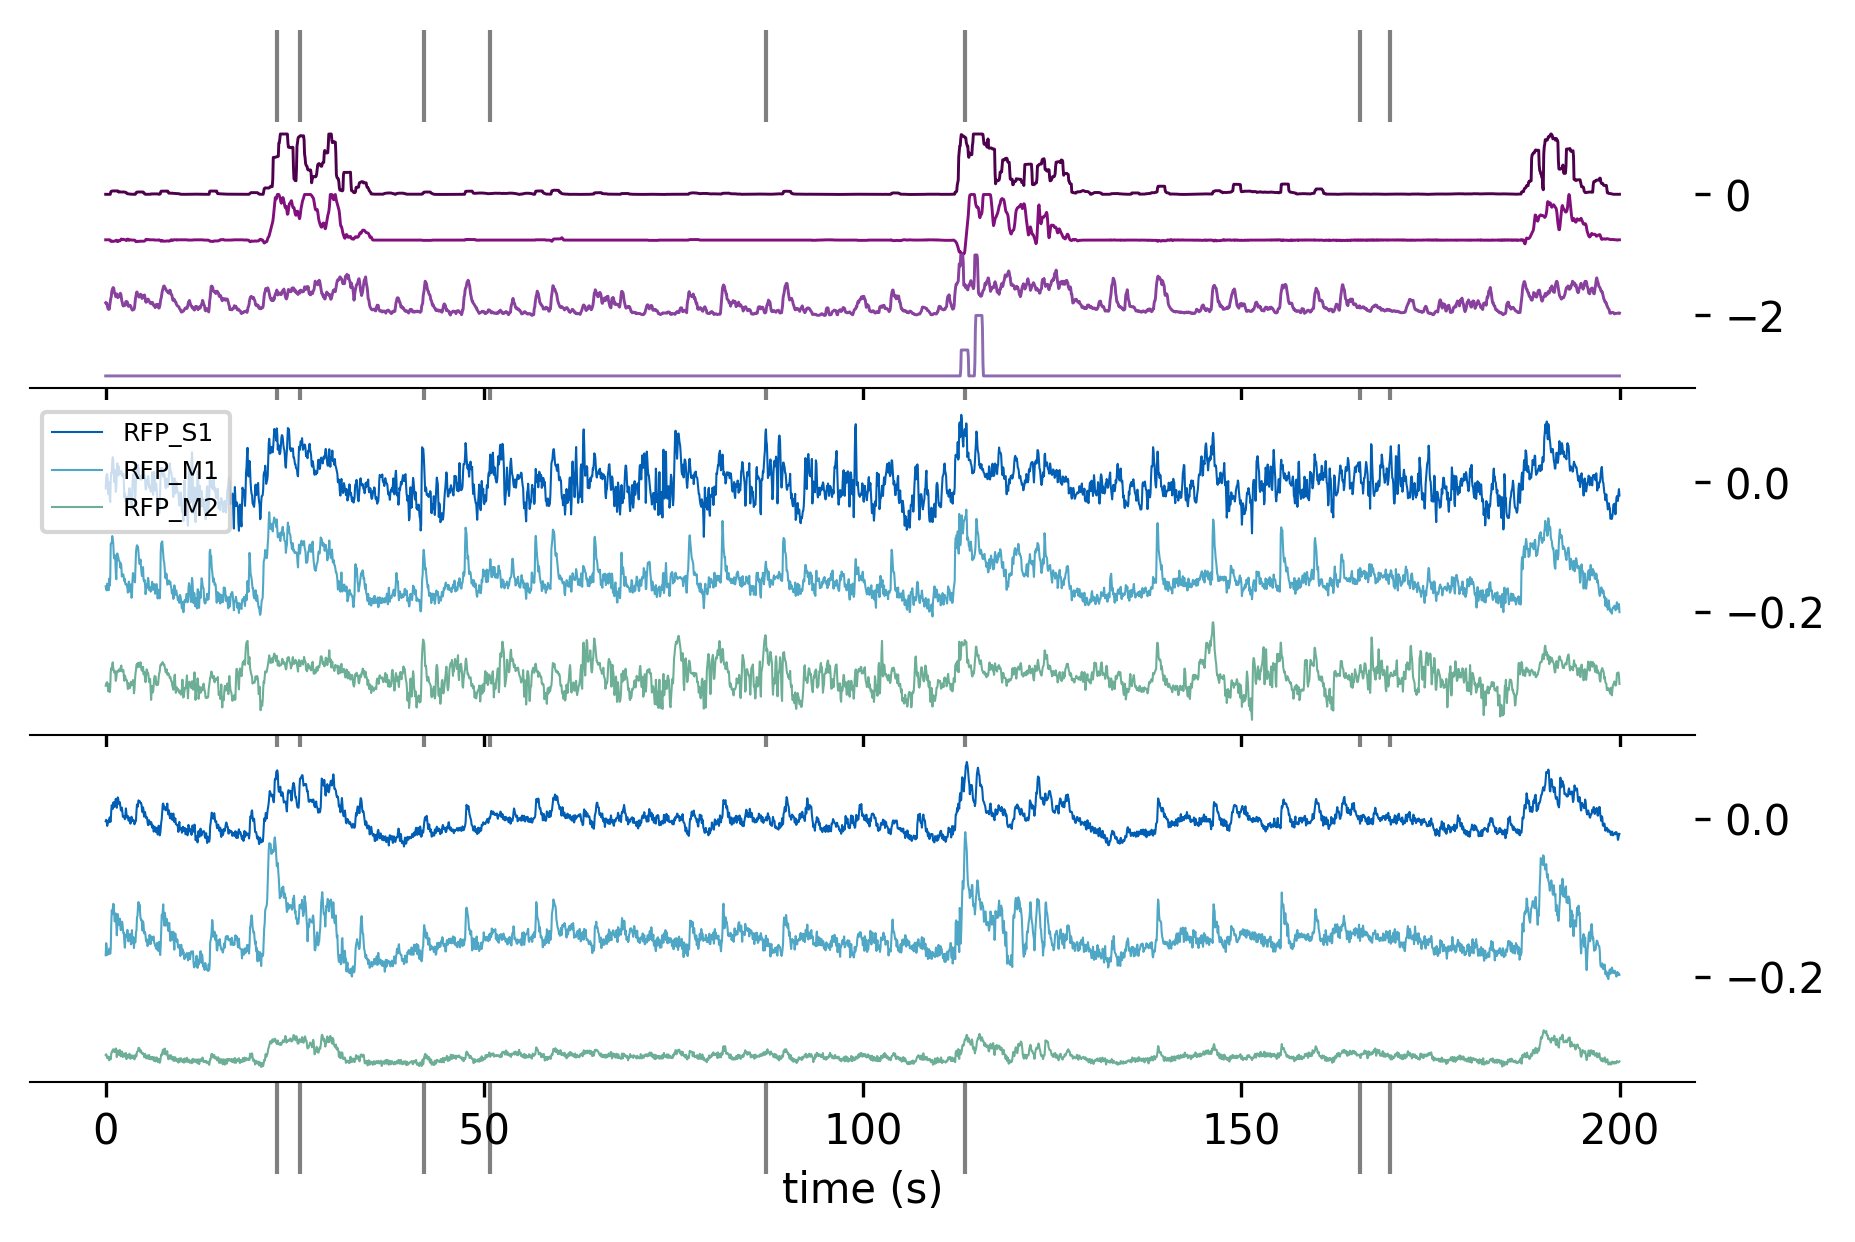

In [18]:
t1 = 340
t2 = 385
t3 = 631
t4 = 761
t5 = 1308
#========
t6 = 1702
t7 = 2485
t8 = 2545

time_series = np.array([t1,t2,t3,t4,t5,t6,t7,t8])
time_range = np.r_[np.arange(1800,3200),np.arange(5850,7450)]
t_tc = np.divide(range(len(time_range)),15)


from matplotlib.gridspec import GridSpec
from skimage import measure
from matplotlib import ticker
import matplotlib

plt.style.use('default')
gs = GridSpec(100,100)

plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset=20;
x_width=24;
x_start = x_offset
x_stop = x_start+x_width
ax0 = fig.add_subplot(gs[y_offset:y_offset+4,x_start:x_stop])
ax1 = fig.add_subplot(gs[y_offset+4:y_offset+9,x_start:x_stop])
ax2 = fig.add_subplot(gs[y_offset+9:y_offset+14,x_start:x_stop])


for i_beh,beh in enumerate(behaviors.keys()):
    ax0.plot(t_tc,normalize(behaviors[beh][time_range])-i_beh*1,linewidth=0.7,color=palatte_3[-i_beh-1],
             label=beh)
    # ax0.text(t_tc[-1]-t_tc[0]+3,-i_beh*1-0.1,beh,color='black',fontsize=8)
    

for i_bdp in range(3):
    bdp = choice_body_part_dict[i_bdp]
    data_2_plot = jrgeco2plot[bdp][time_range]
    ax1.plot(t_tc,data_2_plot-0.15*i_bdp,label=bdp,linewidth=0.5,color=palatte_dict[bdp])
    # ax1.text(t_tc[-1]-t_tc[0]+3,-0.15*i_bdp-0.02,'ROI {} ({}) '.format(i_bdp+1,bdp),color=palatte_dict[bdp],fontsize=8)


for i_bdp in range(3):
    bdp = choice_body_part_dict[i_bdp]
    data_2_plot = gcamp2plot[bdp][time_range]
    ax2.plot(t_tc,data_2_plot-0.15*i_bdp,label=bdp,linewidth=0.5,color=palatte_dict[bdp])
    # ax2.text(t_tc[-1]-t_tc[0]+3,-0.15*i_bdp-0.02,'ROI {} ({}) '.format(i_bdp+1,bdp),color=palatte_dict[bdp],fontsize=8)

 

for axis in ['top','right','left','bottom']:
    for i_ax in range(0,3):
        exec("ax{}.spines[axis].set_linewidth(0.5)".format(i_ax))
for axis in ['top','right','left']:
    for i_ax in range(0,3):
        exec("ax{}.spines[axis].set_linewidth(0)".format(i_ax))
        exec("ax{}.yaxis.tick_right()".format(i_ax))
            
# ax1.set_yticks([]);ax2.set_yticks([]);ax3.set_yticks([])
# ax1.set_xticks([]);ax0.set_xticks([])
ax2.set_xlabel('time (s)')
# for i_ax,ax in enumerate(['0','1','2']):
#     exec("ax{}.set_xlim([-10,371])".format(ax))


for i_t in range(8):
    fig.patches.extend([patches.Polygon([(t_tc[time_series[i_t]],-0.45),(t_tc[time_series[i_t]],1)],
                                      fill=True, color='gray', alpha=1, zorder=-1000,
                                      transform=ax2.transData,
                                      figure=fig)])
    
ax1.legend(fontsize=6)

# ax1.set_ylim([-10,-7])
# ax1.set_yticks([])
# ax1.set_yticks([-2,0])
ax2.set_yticks([-0.2,0])
ax1.set_yticks([-0.2,0])
ax0.set_xticklabels([])
ax1.set_xticklabels([])

ax0.xaxis.set_major_locator(plt.MaxNLocator(5))
ax1.xaxis.set_major_locator(plt.MaxNLocator(5))
ax2.xaxis.set_major_locator(plt.MaxNLocator(5))

plt.savefig('figS6-CSN-single-trial-tc.svg',format='svg',dpi=300)

In [19]:
from scipy.io import savemat

save_dict = {'t_tc': t_tc}

# behaviors (ax0)
for beh in behaviors.keys():
    save_dict['behavior_' + beh] = behaviors[beh][time_range]

# jrgeco and gcamp ROI traces (ax1, ax2)
for i_bdp in range(3):
    bdp = choice_body_part_dict[i_bdp]
    save_dict['jrgeco_' + bdp] = jrgeco2plot[bdp][time_range]
    save_dict['gcamp_' + bdp] = gcamp2plot[bdp][time_range]

savemat('figureS4-CSN-single-trial-tc.mat', save_dict)

In [387]:
# load midline
with h5py.File(figure_config_root+'mask_midline_v2_'+mouse+'.mat','r') as f_midline:
    mask_midline = np.array(f_midline['mask_midline']).T
mask_midline_array = np.repeat(mask_midline[:,:,np.newaxis],repeats=gcamp.shape[-1],axis=2)
jrgeco = np.multiply(jrgeco,mask_midline_array)
gcamp = np.multiply(gcamp,mask_midline_array)


In [210]:
diverging_cmap_gcamp = load_pickle(figure_config_root+'gcamp_diverging_cmap')

In [211]:
# for i_key,key in enumerate(new_choice_ind['cm229']):
#     ind = new_choice_ind['cm229'][key]
#     exec("ax{}.scatter(node_coords[ind,1],node_coords[ind,0],s=3,color=palatte_dict['RFP_'+key])".format(i_ax))
#     exec("ax{}.scatter(node_coords[ind,1],node_coords[ind,0],s=3,facecolors='none',linewidths=0.3, edgecolors='white')".format(i_ax))


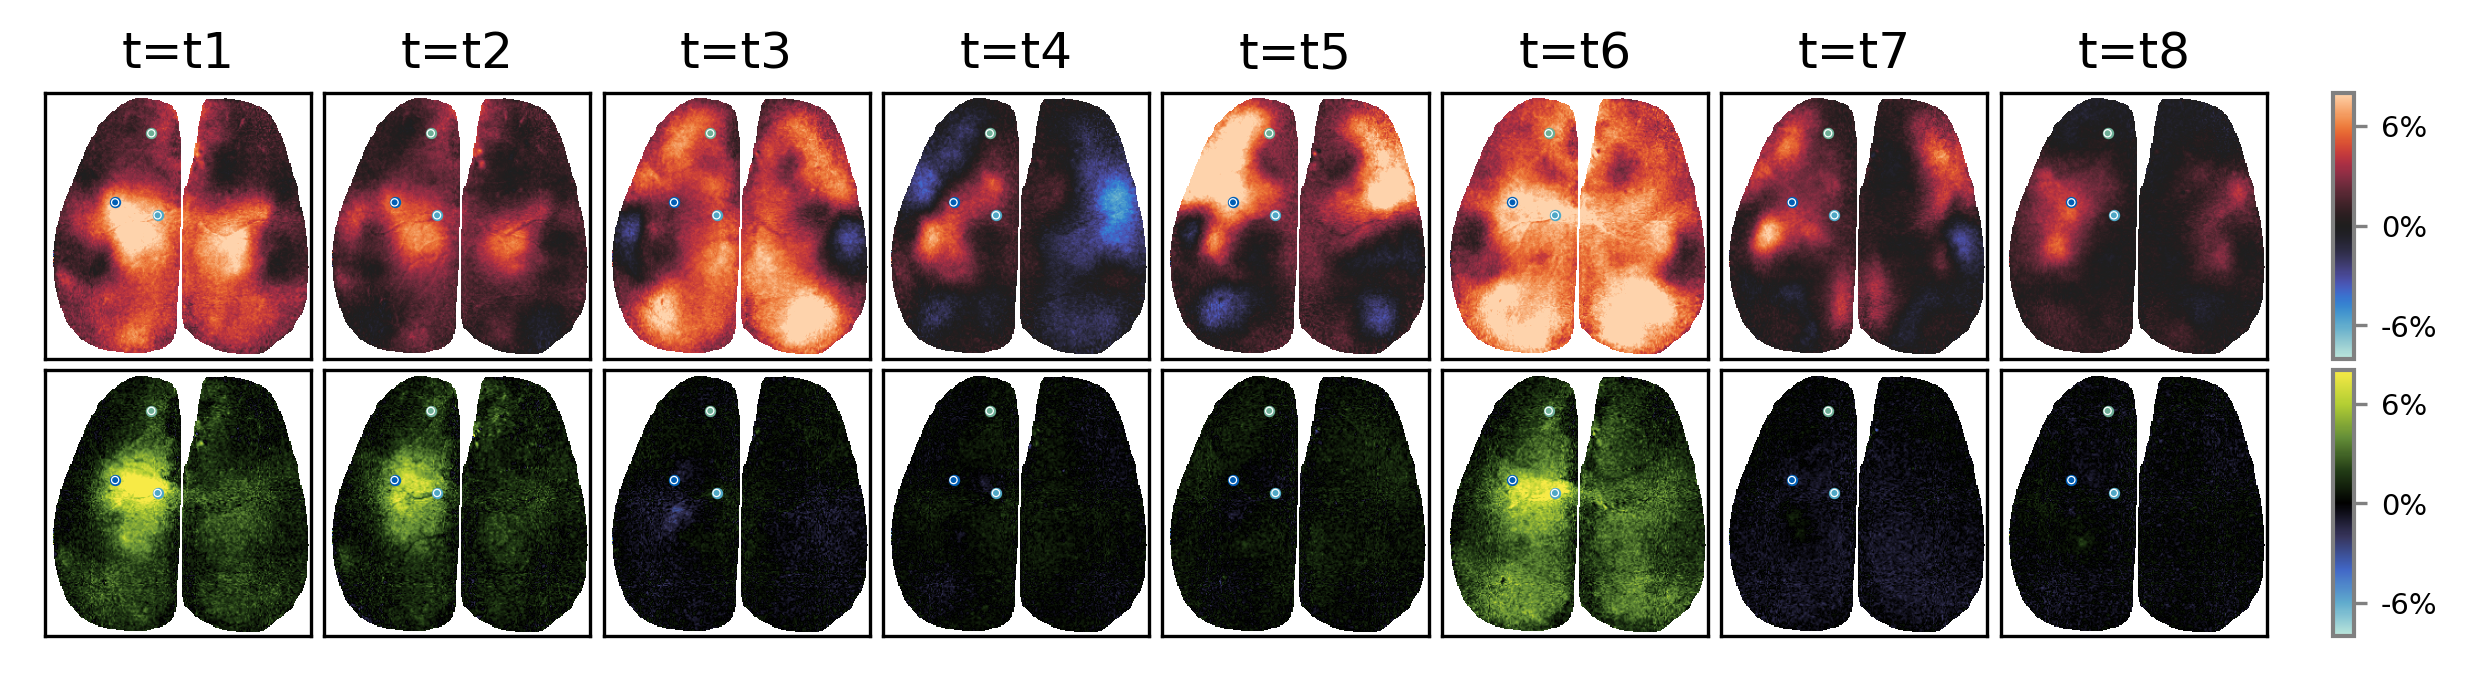

In [395]:
from matplotlib import colors
from skimage import measure
from matplotlib import ticker
import matplotlib
from matplotlib import ticker
from matplotlib.ticker import FuncFormatter
fmt = lambda x, pos: '{:.0%}'.format(x)
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable

time_series_new = time_series.copy()
time_series_new[:5] = time_series_new[:5] + 1800
time_series_new[5:] = time_series_new[5:] + 5850 - 1400

gs = GridSpec(100,100)
# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset=20;y_gap=1;x_gap=0;x_width=4

x_start = x_offset
for i_ax in range(8):
    exec("ax{} = fig.add_subplot(gs[y_offset:y_offset+4,x_start:x_start+4])".format(i_ax))
    x_start = x_start+4+x_gap
    exec("ax{}.set_yticks([])".format(i_ax))
    exec("ax{}.set_xticks([])".format(i_ax))

x_start = x_offset
for i_ax in range(8,16):
    exec("ax{} = fig.add_subplot(gs[y_offset+4:y_offset+8,x_start:x_start+4])".format(i_ax))
    x_start = x_start+4+x_gap
    exec("ax{}.set_yticks([])".format(i_ax))
    exec("ax{}.set_xticks([])".format(i_ax))
    
# x_start = x_offset
# for i_ax in range(14,21):
#     exec("ax{} = fig.add_subplot(gs[y_offset+8:y_offset+12,x_start:x_start+4])".format(i_ax))
#     x_start = x_start+4+x_gap
#     exec("ax{}.set_yticks([])".format(i_ax))
#     exec("ax{}.set_xticks([])".format(i_ax))
    
ax99 = fig.add_subplot(gs[y_offset:y_offset+4,x_start:x_start+2])
ax98 = fig.add_subplot(gs[y_offset+4:y_offset+8,x_start:x_start+2])

########################################################################
for i_t,i_ax in enumerate(range(0,8)):
    exec("sbp{} = ax{}.imshow(jrgeco[:,:,time_series_new[i_t]],vmin=-0.08,vmax=0.08,aspect='equal',cmap='icefire')".format(i_ax,i_ax))
    exec("ax{}.set_xlim([15,256]);ax{}.set_ylim([256,15])".format(i_ax,i_ax))
    for i_key,key in enumerate(['RFP_S1','RFP_M1','RFP_M2']):
        exec("ax{}.scatter(node_coords_all[key][0], node_coords_all[key][1], s=3, c=palatte_dict[key])".format(i_ax))
        exec("ax{}.scatter(node_coords_all[key][0],node_coords_all[key][1],s=3,facecolors='none',linewidths=0.3, edgecolors='white')".format(i_ax))

        
        
    # exec("divider = make_axes_locatable(ax{})".format(i_ax))
    # cax = divider.append_axes('bottom', size='5%', pad=0.05)
    # exec("cb = fig.colorbar(sbp{}, cax=cax, orientation='horizontal',format=FuncFormatter(fmt))".format(i_ax))
    # cb.ax.tick_params(labelsize=7,length=3,color='gray')
for i_t,i_ax in enumerate(range(8,16)):
    exec("sbp{} = ax{}.imshow(gcamp[:,:,time_series_new[i_t]],vmin=-0.08,vmax=0.08,aspect='equal',cmap=diverging_cmap_gcamp)".format(i_ax,i_ax))
    exec("ax{}.set_xlim([15,256]);ax{}.set_ylim([256,15])".format(i_ax,i_ax))
    for i_key,key in enumerate(['RFP_S1','RFP_M1','RFP_M2']):
        exec("ax{}.scatter(node_coords_all[key][0], node_coords_all[key][1], s=3, c=palatte_dict[key])".format(i_ax))
        exec("ax{}.scatter(node_coords_all[key][0],node_coords_all[key][1],s=3,facecolors='none',linewidths=0.3, edgecolors='white')".format(i_ax))

# for i_t,i_ax in enumerate(range(14,21)):   
#     exec("sbp{} = ax{}.imshow(vid_body_clips[time_series[i_t]],cmap='gray')".format(i_ax,i_ax))
#     # add DLC coordinates
#     xx = new_df_trim.iloc[time_series[i_t],0]
#     yy = new_df_trim.iloc[time_series[i_t],1]
#     exec("ax{}.scatter(xx,yy,s=20,color=palatte_dict['LFP'])".format(i_ax))

#     xx = new_df_trim.iloc[time_series[i_t],3]
#     yy = new_df_trim.iloc[time_series[i_t],4]
#     exec("ax{}.scatter(xx,yy,s=20,color=palatte_dict['RFP'])".format(i_ax))
    
#     exec("ax{}.set_xlim([100,360]);ax{}.set_ylim([320,90])".format(i_ax,i_ax))



cb = fig.colorbar(sbp0, cax=ax99,fraction=0.5,orientation='vertical',format=FuncFormatter(fmt));
cb.ax.tick_params(labelsize=7,length=3,color='gray')
cb.ax.yaxis.tick_right()       
cb.outline.set_edgecolor('gray')
cb.outline.set_linewidth(1)
tick_locator = ticker.MaxNLocator(nbins=3)
cb.locator = tick_locator
cb.update_ticks()
ax99.set_aspect(80)

cb = fig.colorbar(sbp10, cax=ax98,fraction=0.5,orientation='vertical',format=FuncFormatter(fmt));
cb.ax.tick_params(labelsize=7,length=3,color='gray')
cb.ax.yaxis.tick_right()       
cb.outline.set_edgecolor('gray')
cb.outline.set_linewidth(1)
tick_locator = ticker.MaxNLocator(nbins=3)
cb.locator = tick_locator
cb.update_ticks()
ax98.set_aspect(80)

for i_t,i_ax in enumerate(range(0,8)):
    exec("ax{}.set_title('t=t{}')".format(i_t,i_t+1))



plt.savefig('figS6-CSN-single-trial-spatial-act.svg',format='svg',dpi=300)

